In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from xgboost import XGBRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error


# ==========================================
# LOAD DATA
# ==========================================

train_raw = pd.read_csv("Train_Data.csv")   # 2025
test_raw = pd.read_csv("Test_Data.csv")     # 2026

train_raw["order_date"] = pd.to_datetime(train_raw["order_date"])
test_raw["order_date"] = pd.to_datetime(test_raw["order_date"])

print("Train:", train_raw["order_date"].min(),
      "→", train_raw["order_date"].max())


print("Test:", test_raw["order_date"].min(),
      "→", test_raw["order_date"].max())

Train: 2025-01-01 00:00:00 → 2025-12-30 00:00:00
Test: 2026-01-01 00:00:00 → 2026-09-11 00:00:00


In [2]:
'''
 2
4
6-7
9-10
11
'''
def is_champain(date):
    month = pd.to_datetime(date).month
    if month == 2 or month == 4 or month == 6 or month == 7 or (month >=9 and month <=11):
        return True
    return False
    




    
    
    
    

In [3]:
# combining only for feature creation
all_data = pd.concat(
    [train_raw, test_raw],
    ignore_index=True
)

all_data['is_champain'] = all_data['order_date'].apply(is_champain)
print("Champain data-> ",all_data[all_data['is_champain'] == True].count())
print("Not Champain data-> ",all_data[all_data['is_champain'] == False].count())



all_data = all_data.sort_values(
    ["product_id", "order_date"]
).reset_index(drop=True)


Champain data->  product_id              221967
product_name            221967
order_date              221967
brand_name              219161
web_category            221482
jeevee_variant_price    221963
qty_invoiced            221967
is_champain             221967
dtype: int64
Not Champain data->  product_id              162041
product_name            162041
order_date              162041
brand_name              159818
web_category            161635
jeevee_variant_price    162038
qty_invoiced            162041
is_champain             162041
dtype: int64


In [4]:
# Only selecting top 3 best selling product
all_data = all_data[
    (all_data['product_id'] == 110457) |
    (all_data['product_id'] == 87350) |
    (all_data['product_id'] == 43482)
]


In [5]:
# Aggregate to daily sales

daily = (
    all_data
    .groupby(
        [
            "product_id",
            "order_date"
        ],
        as_index=False
    )
    .agg(
        sales_qty=("qty_invoiced", "sum"),
        price=("jeevee_variant_price", "mean"),
        product_name=("product_name", "first"),
        brand_name=("brand_name", "first"),
        web_category=("web_category", "first")
    )
)
daily.head()

,product_id,order_date,sales_qty,price,product_name,brand_name,web_category
0,43482,2025-02-04,1,3300.0,ANUA NIACINAMIDE 10% + TXA 4% DARK SPOT SERUM-...,ANUA,SKIN
1,43482,2025-02-05,4,3300.0,ANUA NIACINAMIDE 10% + TXA 4% DARK SPOT SERUM-...,ANUA,SKIN
2,43482,2025-02-06,1,3300.0,ANUA NIACINAMIDE 10% + TXA 4% DARK SPOT SERUM-...,ANUA,SKIN
3,43482,2025-02-07,1,3300.0,ANUA NIACINAMIDE 10% + TXA 4% DARK SPOT SERUM-...,ANUA,SKIN
4,43482,2025-02-08,1,3300.0,ANUA NIACINAMIDE 10% + TXA 4% DARK SPOT SERUM-...,ANUA,SKIN


In [6]:
# Create Complete Dates

products = (
    daily[
        [
            "product_id",
            "product_name",
            "brand_name",
            "web_category"
        ]
    ]
    .drop_duplicates("product_id")
)

dates = pd.DataFrame({
    "order_date": pd.date_range(
        daily["order_date"].min(),
        daily["order_date"].max(),
        freq="D"
    )
})

products["_key"] = 1
dates["_key"] = 1

daily = (
    products
    .merge(dates, on="_key")
    .drop(columns="_key")
)

daily = daily.merge(
    all_data.groupby(
        ["product_id", "order_date"],
        as_index=False
    ).agg(
        sales_qty=("qty_invoiced", "sum"),
        price=("jeevee_variant_price", "mean")
    ),
    on=["product_id", "order_date"],
    how="left"
)

daily["sales_qty"] = daily["sales_qty"].fillna(0)

daily["price"] = (
    daily
    .sort_values(["product_id", "order_date"])
    .groupby("product_id")["price"]
    .ffill()
    .fillna(0)
)

daily = daily.sort_values(
    ["product_id", "order_date"]
).reset_index(drop=True)



In [7]:
group = daily.groupby("product_id")["sales_qty"]

daily["lag_1"] = group.shift(1)
daily["lag_7"] = group.shift(7)
daily["lag_14"] = group.shift(14)
daily["lag_28"] = group.shift(28)



daily[daily['sales_qty']>0].sort_values(['sales_qty'])

,product_id,product_name,brand_name,web_category,order_date,sales_qty,price,lag_1,lag_7,lag_14,lag_28
888,87350,SKIN1004 MADAGASCAR CENTELLA TONE BRIGHTENING ...,SKIN1004,SKIN,2025-12-04,1.0,3500.0,3.0,1.0,1.0,1.0
870,87350,SKIN1004 MADAGASCAR CENTELLA TONE BRIGHTENING ...,SKIN1004,SKIN,2025-11-16,1.0,3500.0,1.0,1.0,1.0,0.0
869,87350,SKIN1004 MADAGASCAR CENTELLA TONE BRIGHTENING ...,SKIN1004,SKIN,2025-11-15,1.0,3500.0,1.0,1.0,1.0,1.0
868,87350,SKIN1004 MADAGASCAR CENTELLA TONE BRIGHTENING ...,SKIN1004,SKIN,2025-11-14,1.0,3500.0,3.0,1.0,1.0,1.0
865,87350,SKIN1004 MADAGASCAR CENTELLA TONE BRIGHTENING ...,SKIN1004,SKIN,2025-11-11,1.0,3500.0,3.0,0.0,1.0,3.0
...,...,...,...,...,...,...,...,...,...,...,...
496,43482,ANUA NIACINAMIDE 10% + TXA 4% DARK SPOT SERUM-...,ANUA,SKIN,2026-06-15,8.0,3300.0,1.0,1.0,1.0,1.0
1733,110457,FAIRY SKIN TINTED SUNSCREEN SPF 50 PA ++++ SHE...,FAIRY SKIN,SKIN,2026-08-21,9.0,1800.0,3.0,1.0,15.0,3.0
1644,110457,FAIRY SKIN TINTED SUNSCREEN SPF 50 PA ++++ SHE...,FAIRY SKIN,SKIN,2026-05-24,10.0,1800.0,3.0,6.0,0.0,3.0
1731,110457,FAIRY SKIN TINTED SUNSCREEN SPF 50 PA ++++ SHE...,FAIRY SKIN,SKIN,2026-08-19,11.0,1800.0,1.0,1.0,3.0,1.0


In [8]:
# Rolling Feature


daily["rolling_mean_7"] = (
    group.shift(1)
    .rolling(7)
    .mean()
    .reset_index(level=0, drop=True)
)

daily["rolling_mean_14"] = (
    group.shift(1)
    .rolling(14)
    .mean()
    .reset_index(level=0, drop=True)
)

daily["rolling_mean_30"] = (
    group.shift(1)
    .rolling(30)
    .mean()
    .reset_index(level=0, drop=True)
)

daily["rolling_std_7"] = (
    group.shift(1)
    .rolling(7)
    .std()
    .reset_index(level=0, drop=True)
)

daily["rolling_std_30"] = (
    group.shift(1)
    .rolling(30)
    .std()
    .reset_index(level=0, drop=True)
)

daily.columns

Index(['product_id', 'product_name', 'brand_name', 'web_category',
       'order_date', 'sales_qty', 'price', 'lag_1', 'lag_7', 'lag_14',
       'lag_28', 'rolling_mean_7', 'rolling_mean_14', 'rolling_mean_30',
       'rolling_std_7', 'rolling_std_30'],
      dtype='str')

In [9]:
# Active Days
daily["active_day"] = (
    daily["sales_qty"] > 0
).astype(int)

active_group = daily.groupby("product_id")["active_day"]

daily["active_days_7"] = (
    active_group.shift(1)
    .rolling(7)
    .sum()
    .reset_index(level=0, drop=True)
)

daily["active_days_30"] = (
    active_group.shift(1)
    .rolling(30)
    .sum()
    .reset_index(level=0, drop=True)
)

In [10]:
# ADU


daily["sales_7"] = (
    group.shift(1)
    .rolling(7)
    .sum()
    .reset_index(level=0, drop=True)
)

daily["sales_30"] = (
    group.shift(1)
    .rolling(30)
    .sum()
    .reset_index(level=0, drop=True)
)

daily["adu_7"] = (
    daily["sales_7"] /
    daily["active_days_7"].replace(0, np.nan)
)

daily["adu_30"] = (
    daily["sales_30"] /
    daily["active_days_30"].replace(0, np.nan)
)


In [11]:
# Calender Feature


daily["day_of_week"] = (
    daily["order_date"].dt.dayofweek
)

daily["day_of_month"] = (
    daily["order_date"].dt.day
)

daily["month"] = (
    daily["order_date"].dt.month
)

daily["week_of_year"] = (
    daily["order_date"]
    .dt.isocalendar()
    .week
    .astype(int)
)

daily["is_weekend"] = (
    daily["day_of_week"] >= 5
).astype(int)

# The model predicts NEXT day's sales (target = shift(-1)), so we also keep the
# date that the target actually belongs to. Used for the train/test split and
# for the chart x-axis, so "2026-06-01" really means sales ON 2026-06-01.
daily["target_date"] = daily["order_date"] + pd.Timedelta(days=1)

# Campaign flag (months 2, 4, 6, 7, 9, 10, 11) - based on the day being
# predicted, since campaign dates are known in advance.
daily["is_champain"] = daily["target_date"].apply(is_champain).astype(int)

In [12]:
# Target

daily["target"] = (
    daily
    .groupby("product_id")["sales_qty"]
    .shift(-1)
)

## New features: category/brand cross-sectional signal + product age

Addresses the cold-start problem: brand-new products (zero sales in 2025)
have every lag/rolling/ADU feature equal to 0, so the model has no way to
tell a dead product from one about to ramp up. These features give it a
fallback signal (what similar products are doing) and a sense of product age.

In [13]:
# Category / brand level average daily sales, lagged by 1 day to avoid leakage.
# This gives new products (which have no own history) a cross-sectional
# fallback signal based on how similar products are currently selling.

cat_daily = (
    daily.groupby(["web_category", "order_date"], as_index=False, dropna=False)["sales_qty"]
    .mean()
    .rename(columns={"sales_qty": "category_avg_sales"})
)

cat_daily["category_avg_sales_lag1"] = (
    cat_daily.groupby("web_category")["category_avg_sales"]
    .shift(1)
)

daily = daily.merge(
    cat_daily[["web_category", "order_date", "category_avg_sales_lag1"]],
    on=["web_category", "order_date"],
    how="left",
)

brand_daily = (
    daily.groupby(["brand_name", "order_date"], as_index=False, dropna=False)["sales_qty"]
    .mean()
    .rename(columns={"sales_qty": "brand_avg_sales"})
)

brand_daily["brand_avg_sales_lag1"] = (
    brand_daily.groupby("brand_name")["brand_avg_sales"]
    .shift(1)
)

daily = daily.merge(
    brand_daily[["brand_name", "order_date", "brand_avg_sales_lag1"]],
    on=["brand_name", "order_date"],
    how="left",
)

In [14]:
# Product age: days since this product's first recorded sale.
# Lets the tree learn launch/ramp-up curves instead of treating every
# zero-history product as identical. -1 = no sale recorded yet (pre-launch
# or truly dead product).

first_sale_date = (
    daily[daily["sales_qty"] > 0]
    .groupby("product_id")["order_date"]
    .min()
    .rename("first_sale_date")
)

daily = (
    daily.drop(columns=["first_sale_date"], errors="ignore")
    .merge(first_sale_date, on="product_id", how="left")
)

daily["days_since_first_sale"] = (
    (daily["order_date"] - daily["first_sale_date"]).dt.days
)

daily["days_since_first_sale"] = daily["days_since_first_sale"].fillna(-1)

# Before the first sale the product has no age yet. Without this line the value
# would go negative and quietly reveal when the first sale happens (future info).
daily.loc[daily["days_since_first_sale"] < 0, "days_since_first_sale"] = -1

daily["is_cold_start"] = (daily["active_days_30"].fillna(0) == 0).astype(int)

In [15]:
# Feature list (updated: added cross-sectional brand/category signal,
# product age, and brand/category as categorical features so the model
# has something to go on for zero-history products)

numeric_features = [
    "lag_1",
    "lag_7",
    "lag_14",
    "lag_28",

    "rolling_mean_7",
    "rolling_mean_14",
    "rolling_mean_30",

    "rolling_std_7",
    "rolling_std_30",

    "active_days_7",
    "active_days_30",

    "sales_7",
    "sales_30",

    "adu_7",
    "adu_30",

    "price",

    "day_of_week",
    "day_of_month",
    "month",
    "week_of_year",
    "is_weekend",
    "is_champain",

    "days_since_first_sale",
    "category_avg_sales_lag1",
    "brand_avg_sales_lag1",
]

categorical_features = [
    "web_category",
    "brand_name",
]

features = numeric_features + categorical_features

In [16]:
# Clean
# Numeric features: fill missing/inf with 0, as before.
# Categorical features: fill missing with an explicit "UNKNOWN" category
# instead of 0 (0 has no meaning for a brand/category string column), and
# cast to category dtype so XGBoost's enable_categorical=True can use them.

daily = daily.replace(
    [np.inf, -np.inf],
    np.nan
)

daily[numeric_features] = (
    daily[numeric_features]
    .fillna(0)
)

for col in categorical_features:
    daily[col] = daily[col].fillna("UNKNOWN").astype("category")

In [17]:
# Split by the date the sales actually happened (target_date)
#   Train: everything up to 31 May 2026
#   Test : 1 Jun 2026 -> 31 Aug 2026  (June, July, August)

TRAIN_END  = "2026-05-31"
TEST_START = "2026-06-01"
TEST_END   = "2026-08-31"

train = daily[daily["target_date"] <= TRAIN_END].dropna(subset=["target"]).copy()

test = daily[
    (daily["target_date"] >= TEST_START) &
    (daily["target_date"] <= TEST_END)
].copy()

In [18]:
print("Train sales dates:", train["target_date"].min().date(),
      "->", train["target_date"].max().date(), f"({len(train)} rows)")

print("Test  sales dates:", test["target_date"].min().date(),
      "->", test["target_date"].max().date(), f"({len(test)} rows)")

Train sales dates: 2025-02-05 -> 2026-05-31 (1443 rows)
Test  sales dates: 2026-06-01 -> 2026-08-31 (276 rows)


In [19]:
# don't use 2026 target during preduction
X_train = train[features]
y_train = train["target"]

X_test = test[features]
y_test = test["target"]

In [20]:
# Train XGBOOST
model = XGBRegressor(
    n_estimators=500,
    max_depth=10,
    learning_rate=0.05,

    subsample=0.8,
    colsample_bytree=0.8,

    objective="reg:squarederror",

    random_state=42,
    n_jobs=-1
)

model.fit(
    X_train,
    y_train
)

,"base_score base_score: float | typing.List[float] | NoneThe initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.List[xgboost.callback.TrainingCallback] | NoneList of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: float | NoneSubsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: float | NoneSubsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: float | NoneSubsample ratio of columns when constructing each tree.,0.8
,"device device: str | None.. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: int | None.. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,True
,"eval_metric eval_metric: str | typing.List[str | typing.Callable] | typing.Callable | None.. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from sklearn.metrics import mean_absolute_error X, y = load_diabetes(return_X_y=True) reg = xgb.XGBRegressor( tree_method=""hist"", eval_metric=mean_absolute_error, ) reg.fit(X, y, eval_set=[(X, y)])",None
,feature_types feature_types: typing.Sequence[str] | None.. versionadded:: 1.7.0Used for specifying feature types without constructing a dataframe. Seethe :py:class:`DMatrix` for details.,None


In [21]:
# Predict 2026
predictions = model.predict(X_test)

predictions = np.maximum(
    predictions,
    0
)

## Two-part approach: blend in a cold-start fallback

For products with no sales in the trailing 30 days (new launches or fully
dormant SKUs), the model's own-history features are all 0/UNKNOWN, so its
prediction is essentially a guess. For those rows only, blend the model's
prediction with a simple cross-sectional fallback (recent category/brand
average demand). Established products (the majority) are left untouched.

In [22]:
test = test.reset_index(drop=True)

fallback = (
    test["category_avg_sales_lag1"]
    .fillna(test["brand_avg_sales_lag1"])
    .fillna(0)
)

is_cold_start = (test["is_cold_start"] == 1).to_numpy()

blended_predictions = np.where(
    is_cold_start,
    0.5 * predictions + 0.5 * fallback.to_numpy(),
    predictions,
)

print("Cold-start rows in test set:", is_cold_start.sum())
print("Of", len(test), "total test rows")

Cold-start rows in test set: 0
Of 276 total test rows


In [23]:

valid = y_test.notna()

y_test_clean = y_test[valid]
predictions_clean = predictions[valid.to_numpy()]
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

mae = mean_absolute_error(
    y_test_clean,
    predictions_clean
)

rmse = np.sqrt(
    mean_squared_error(
        y_test_clean,
        predictions_clean
    )
)

print("MAE :", round(mae, 2))
print("RMSE:", round(rmse, 2))



active = y_test_clean > 0

mae_active = mean_absolute_error(
    y_test_clean[active],
    predictions_clean[active]
)

rmse_active = np.sqrt(
    mean_squared_error(
        y_test_clean[active],
        predictions_clean[active]
    )
)

print("Active demand rows:", active.sum())
print("MAE on active demand :", round(mae_active, 2))
print("RMSE on active demand:", round(rmse_active, 2))

MAE : 0.9
RMSE: 1.63
Active demand rows: 232
MAE on active demand : 0.91
RMSE on active demand: 1.74


In [24]:
# Create Result

results = test[
    [
        "product_id",
        "product_name",
        "order_date",
        "target_date",
        "is_cold_start",
    ]
].copy()

results["actual"] = y_test.values
results["predicted"] = predictions
results["predicted_blended"] = blended_predictions

# Drop rows with no real target, then add the naive baseline for comparison.
results_clean = results[results["actual"].notna()].copy()

# Naive baseline = ONE FLAT average per product per month (no model needed).
#   "previous_30_days": average daily sales (all days counted, zero-sale days
#                       included) of the 30 days BEFORE the month starts.
#                       Known in advance, so it is a fair forecast.
#   "same_month_actual": the month's own actual average. That is hindsight, so it
#                       scores ~100% by construction - only use it as a reference line.
BASELINE_MODE = "previous_30_days"

results_clean["month"] = results_clean["target_date"].dt.to_period("M")

flat_avg = {}
for (pid, m), g in results_clean.groupby(["product_id", "month"]):
    if BASELINE_MODE == "previous_30_days":
        month_start = m.start_time
        window = daily[
            (daily["product_id"] == pid) &
            (daily["order_date"] >= month_start - pd.Timedelta(days=30)) &
            (daily["order_date"] < month_start)
        ]
        flat_avg[(pid, m)] = window["sales_qty"].mean()
    else:
        flat_avg[(pid, m)] = g["actual"].mean()

results_clean["predicted_avg"] = [
    flat_avg[(p, m)] for p, m in zip(results_clean["product_id"], results_clean["month"])
]

## Error breakdown: new/cold-start products vs. established products

Quantifies how much of the total error is coming from products that had
little or no history in 2025 (cold start) versus products the model has
real history for. This tells us whether to prioritize the cold-start fix
above or the extrapolation-ceiling issue for established, high-volume SKUs.

In [25]:
# Error breakdown: new vs established products
# (with only the top-3 sellers there may be no "new" products - handled below)

def safe_mae(y, p):
    return mean_absolute_error(y, p) if len(y) else float("nan")

def safe_rmse(y, p):
    return np.sqrt(mean_squared_error(y, p)) if len(y) else float("nan")

max_train = train.groupby("product_id")["sales_qty"].max()
new_products = max_train[max_train == 0].index

new_mask = results_clean["product_id"].isin(new_products)

print("New-product rows (no sales in training data):", new_mask.sum())
print("Established-product rows:", (~new_mask).sum())
print()

for label, preds_col in [
    ("raw model prediction", "predicted"),
    ("blended (with cold-start fallback)", "predicted_blended"),
    ("naive baseline (flat average)", "predicted_avg"),
]:
    a_all, p_all = results_clean["actual"], results_clean[preds_col]
    a_new, p_new = results_clean.loc[new_mask, "actual"], results_clean.loc[new_mask, preds_col]
    a_est, p_est = results_clean.loc[~new_mask, "actual"], results_clean.loc[~new_mask, preds_col]

    print(f"--- {label} ---")
    print(f"  Overall:               MAE={safe_mae(a_all, p_all):.3f}  RMSE={safe_rmse(a_all, p_all):.3f}")
    print(f"  New products:          MAE={safe_mae(a_new, p_new):.3f}  RMSE={safe_rmse(a_new, p_new):.3f}")
    print(f"  Established products:  MAE={safe_mae(a_est, p_est):.3f}  RMSE={safe_rmse(a_est, p_est):.3f}")
    print()

New-product rows (no sales in training data): 0
Established-product rows: 276

--- raw model prediction ---
  Overall:               MAE=0.900  RMSE=1.634
  New products:          MAE=nan  RMSE=nan
  Established products:  MAE=0.900  RMSE=1.634

--- blended (with cold-start fallback) ---
  Overall:               MAE=0.900  RMSE=1.634
  New products:          MAE=nan  RMSE=nan
  Established products:  MAE=0.900  RMSE=1.634

--- naive baseline (flat average) ---
  Overall:               MAE=0.980  RMSE=1.636
  New products:          MAE=nan  RMSE=nan
  Established products:  MAE=0.980  RMSE=1.636



## ADU and next-30-day sales, month by month (Month 1 = Jun, Month 2 = Jul, Month 3 = Aug)

Whole-month numbers only (no per-day rows): 3 rows per product, one per month, plus 3 rows for all products together.

- **ADU** (average daily units) = units in the month / days in the month
- **30-day sales** = ADU x 30, so every month is on the same 30-day footing
- shown for what **actually happened**, what **XGBoost** predicted, and what the **flat average** predicted (one flat number per month, from the 30 days before the month)
- accuracy = `100% - |predicted - actual| / actual` (same % for ADU and 30-day sales)

Note: monthly numbers are the sum of the daily predictions, and each daily prediction uses real sales up to the day before. A forecast made blind on day 1 of the month would be less accurate than this.

In [26]:
rc = results_clean.copy()
rc["month"] = rc["target_date"].dt.to_period("M")

month_order = sorted(rc["month"].unique())
month_label = {m: f"Month {i+1} ({m.strftime('%b %Y')})" for i, m in enumerate(month_order)}


def volume_acc(actual_u, pred_u):
    """100% - |predicted - actual| / actual, floored at 0."""
    if actual_u == 0:
        return np.nan
    return max(0.0, 1 - abs(pred_u - actual_u) / actual_u) * 100


def month_row(group_name, label, g):
    days = g["target_date"].nunique()
    actual_u = g["actual"].sum()
    xgb_u = g["predicted"].sum()
    avg_u = g["predicted_avg"].sum()

    xgb_acc, avg_acc = volume_acc(actual_u, xgb_u), volume_acc(actual_u, avg_u)

    if np.isnan(xgb_acc) or np.isnan(avg_acc):
        better = "n/a"
    elif abs(xgb_acc - avg_acc) < 0.05:
        better = "tie"
    else:
        better = "XGBoost" if xgb_acc > avg_acc else "Flat average"

    return {
        "group": group_name,
        "month": label,
        "days": days,
        "actual_ADU": round(actual_u / days, 2),
        "xgb_ADU": round(xgb_u / days, 2),
        "avg_ADU": round(avg_u / days, 2),
        "actual_30d_sales": round(actual_u / days * 30),
        "xgb_30d_sales": round(xgb_u / days * 30),
        "avg_30d_sales": round(avg_u / days * 30),
        "xgb_acc_%": round(xgb_acc, 1),
        "avg_acc_%": round(avg_acc, 1),
        "better": better,
    }


monthly_groups = [(f"ALL {rc['product_id'].nunique()} PRODUCTS", rc)]
for pid, g in rc.groupby("product_id"):
    monthly_groups.append((f"{pid} - {g['product_name'].iloc[0][:30]}", g))

monthly_rows = []
for gname, gdf in monthly_groups:
    for m in month_order:
        part = gdf[gdf["month"] == m]
        if len(part):
            monthly_rows.append(month_row(gname, month_label[m], part))

monthly_df = pd.DataFrame(monthly_rows)
pd.set_option("display.width", 250)
pd.set_option("display.max_columns", None)
display(monthly_df)

print()
print("Plain English (all products together):")
for _, r in monthly_df[monthly_df["group"].str.startswith("ALL")].iterrows():
    print(f"{r['month']}: customers bought about {r['actual_ADU']:.1f} units/day ({r['actual_30d_sales']:,.0f} per 30 days). "
          f"XGBoost said {r['xgb_ADU']:.1f}/day ({r['xgb_30d_sales']:,.0f}) -> {r['xgb_acc_%']:.0f}% accurate. "
          f"flat average said {r['avg_ADU']:.1f}/day ({r['avg_30d_sales']:,.0f}) -> {r['avg_acc_%']:.0f}% accurate.")

,group,month,days,actual_ADU,xgb_ADU,avg_ADU,actual_30d_sales,xgb_30d_sales,avg_30d_sales,xgb_acc_%,avg_acc_%,better
0,ALL 3 PRODUCTS,Month 1 (Jun 2026),30,5.87,4.27,3.93,176,128,118,72.8,67.0,XGBoost
1,ALL 3 PRODUCTS,Month 2 (Jul 2026),31,3.58,4.20,5.87,107,126,176,82.8,36.2,XGBoost
2,ALL 3 PRODUCTS,Month 3 (Aug 2026),31,5.00,4.56,3.60,150,137,108,91.2,72.0,XGBoost
3,43482 - ANUA NIACINAMIDE 10% + TXA 4%,Month 1 (Jun 2026),30,1.30,0.97,0.77,39,29,23,74.3,59.0,XGBoost
4,43482 - ANUA NIACINAMIDE 10% + TXA 4%,Month 2 (Jul 2026),31,0.35,0.88,1.30,11,26,39,0.0,0.0,tie
5,43482 - ANUA NIACINAMIDE 10% + TXA 4%,Month 3 (Aug 2026),31,0.84,1.05,0.33,25,32,10,74.2,39.7,XGBoost
6,87350 - SKIN1004 MADAGASCAR CENTELLA T,Month 1 (Jun 2026),30,1.43,1.18,0.23,43,35,7,82.2,16.3,XGBoost
7,87350 - SKIN1004 MADAGASCAR CENTELLA T,Month 2 (Jul 2026),31,0.74,0.83,1.43,22,25,43,87.7,6.8,XGBoost
8,87350 - SKIN1004 MADAGASCAR CENTELLA T,Month 3 (Aug 2026),31,1.06,0.95,0.73,32,29,22,89.5,68.9,XGBoost
9,110457 - FAIRY SKIN TINTED SUNSCREEN SP,Month 1 (Jun 2026),30,3.13,2.13,2.93,94,64,88,67.9,93.6,Flat average



Plain English (all products together):
Month 1 (Jun 2026): customers bought about 5.9 units/day (176 per 30 days). XGBoost said 4.3/day (128) -> 73% accurate. flat average said 3.9/day (118) -> 67% accurate.
Month 2 (Jul 2026): customers bought about 3.6 units/day (107 per 30 days). XGBoost said 4.2/day (126) -> 83% accurate. flat average said 5.9/day (176) -> 36% accurate.
Month 3 (Aug 2026): customers bought about 5.0 units/day (150 per 30 days). XGBoost said 4.6/day (137) -> 91% accurate. flat average said 3.6/day (108) -> 72% accurate.


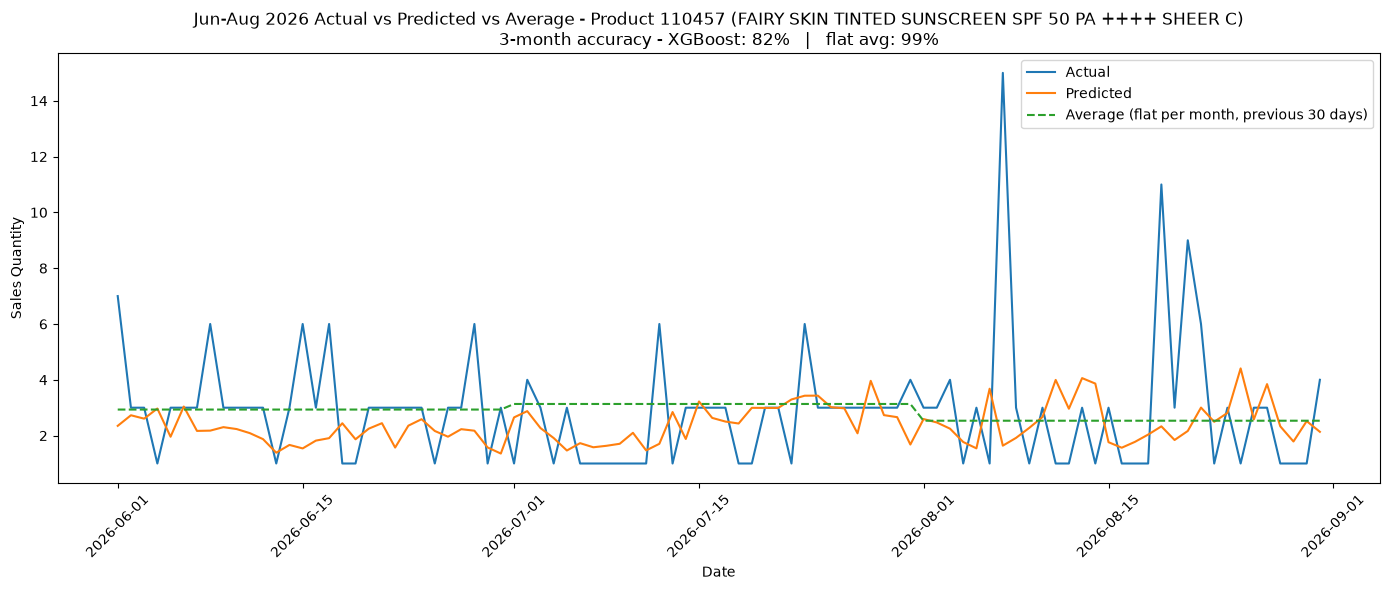

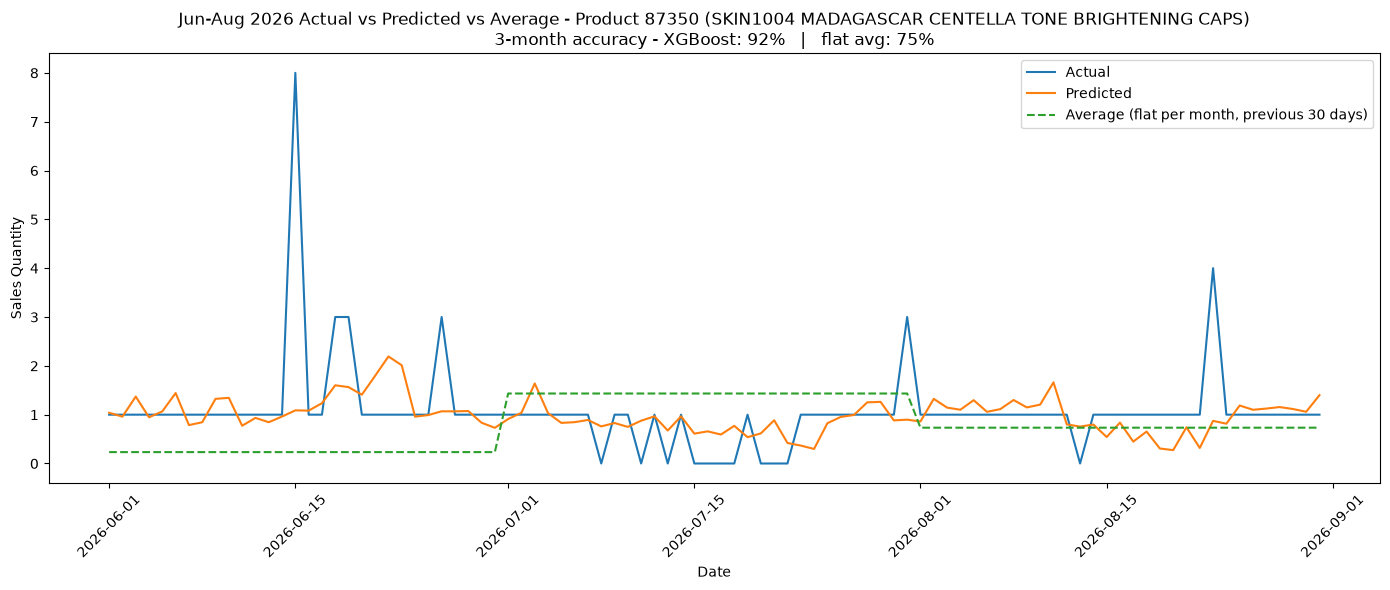

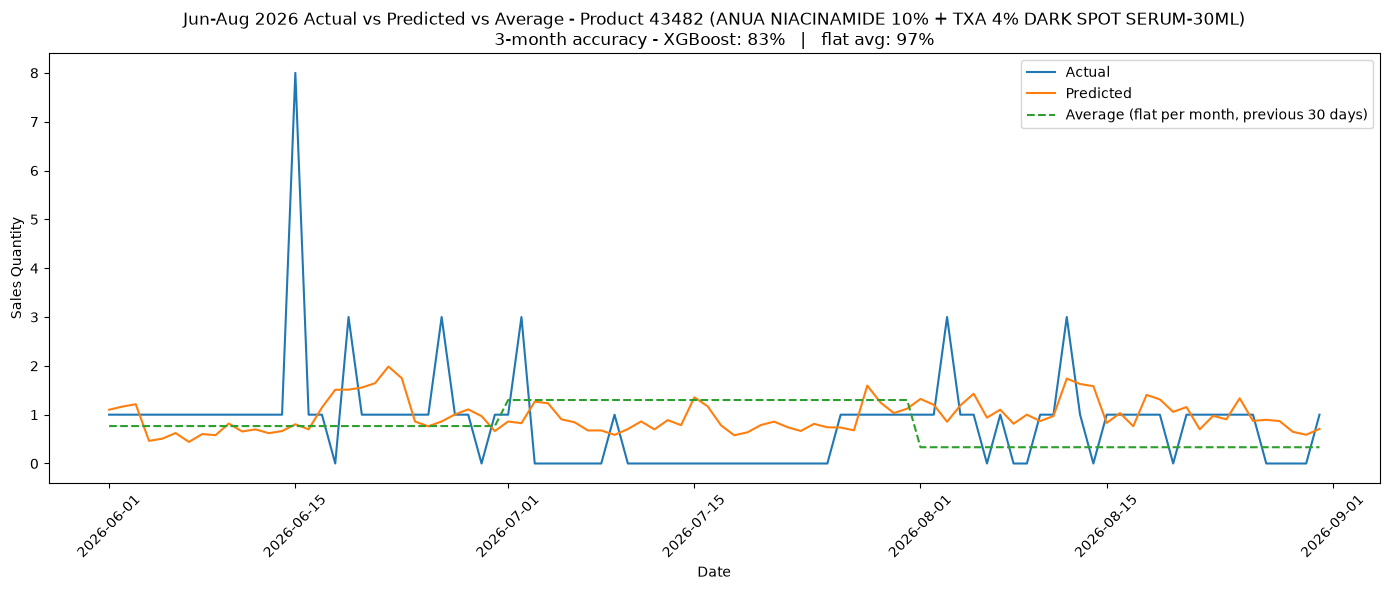

In [27]:
# One chart per product (Actual vs Predicted vs flat average), Jun-Aug 2026
product_ids = [110457, 87350, 43482]

for pid in product_ids:
    g = results_clean[results_clean["product_id"] == pid].sort_values("target_date")

    if g.empty:
        print(f"No test rows for product {pid}")
        continue

    xgb_acc = volume_acc(g["actual"].sum(), g["predicted"].sum())
    avg_acc = volume_acc(g["actual"].sum(), g["predicted_avg"].sum())
    name = g["product_name"].iloc[0][:50]

    plt.figure(figsize=(14, 6))

    plt.plot(g["target_date"], g["actual"], label="Actual")
    plt.plot(g["target_date"], g["predicted"], label="Predicted")
    plt.plot(
        g["target_date"],
        g["predicted_avg"],
        label="Average (flat per month, previous 30 days)",
        linestyle="--"
    )

    plt.xlabel("Date")
    plt.ylabel("Sales Quantity")

    plt.title(
        f"Jun-Aug 2026 Actual vs Predicted vs Average - Product {pid} ({name})\n"
        f"3-month accuracy - XGBoost: {xgb_acc:.0f}%   |   flat avg: {avg_acc:.0f}%"
    )

    plt.legend()
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()